# Week 8 – High Frequency Words
**Corpus:** `rec.sport.baseball` newsgroup posts (20 Newsgroups dataset)

Questions answered below:
1. Choose a corpus
2. Total unique words
3. Unique words that make up half of all words
4. 200 highest-frequency words
5. Graph of their relative frequency
6. Does it follow Zipf's law?
7. How does this differ from "all words in all corpora"?

## Setup

In [12]:
# If a package is missing, uncomment the next line and run once:
# %pip install scikit-learn pandas numpy matplotlib nltk

import re
from collections import Counter

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

pd.set_option("display.max_rows", 250)

In [13]:
# Build the stopword set
stop_words = set(stopwords.words("english"))  | set(ENGLISH_STOP_WORDS)

In [14]:
stopwords

<WordListCorpusReader in '/Users/Audiorunner13/nltk_data/corpora/stopwords'>

## 1. Corpus
#### The **`rec.sport.baseball`** group from the 20 Newsgroups dataset: informal posts by baseball fans (game discussion, stats, trades, arguments about players). I strip email headers, signatures, and quoted replies so repeated quoted text doesn't inflate the counts.

In [15]:
data = fetch_20newsgroups(
    subset="all",
    categories=["rec.sport.baseball"],
    remove=("headers", "footers", "quotes"),
)
docs = data.data
print(f"Number of posts: {len(docs):,}")
print("\nSample post:\n", docs[0][:500])

Number of posts: 994

Sample post:
 I hear ya!  Then again, we must remember that we are indeed Cub fans, and
that the Cubs will eventually blow it.  After all, the Cubs are the easiest
team in the National League to root for.  No Pressure.  You know they will
lose eventually.  Oh well, I suppose we must have faith.  After all, they
do look pretty good, and they don't even have Sandberg back yet.  

CUBS IN '93!!!!!


## 2. How many unique words?
#### Tokenization choices (stated explicitly so they are defensible):
#### - Lowercase everything, so "Game" and "game" count as one word.
#### - Keep only alphabetic tokens, allowing an internal apostrophe ("don't", "team's").
#### - Drop pure numbers (scores, years, stats). They are interesting, but they inflate the unique count without being words.

In [16]:
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

tokens = []
for doc in docs:
    tokens += TOKEN_RE.findall(doc.lower())

counts = Counter(tokens)
total_tokens = len(tokens)
unique_words = len(counts)
hapax = sum(1 for c in counts.values() if c == 1)

# Alternative definitions for comparison
raw_split = [w for doc in docs for w in doc.split()]
alt = pd.DataFrame({
    "definition": [
        "Whitespace split, case-sensitive (raw)",
        "Lowercase, alphabetic only (my definition)",
        "My definition, minus words seen only once",
    ],
    "unique_words": [len(set(raw_split)), unique_words, unique_words - hapax],
})

print(f"Total tokens: {total_tokens:,}")
print(f"Unique words (my definition): {unique_words:,}")
print(f"Words appearing exactly once: {hapax:,} ({hapax/unique_words:.1%} of unique words)")
alt

Total tokens: 115,436
Unique words (my definition): 9,155
Words appearing exactly once: 4,095 (44.7% of unique words)


,definition,unique_words
0,"Whitespace split, case-sensitive (raw)",20532
1,"Lowercase, alphabetic only (my definition)",9155
2,"My definition, minus words seen only once",5060


In [17]:
# Filtered tokens and counts
filtered_tokens = [w for w in tokens if w not in stop_words]
filtered_counts = Counter(filtered_tokens)

print(f"Tokens before: {len(tokens):,}  after: {len(filtered_tokens):,}")
print(f"Unique words before: {len(counts):,}  after: {len(filtered_counts):,}")
print(filtered_counts.most_common(20))

# To rebuild the frequency table from the filtered data, so Q3 through Q6 use it, replace the freq setup with this:

total_tokens = len(filtered_tokens)

Tokens before: 115,436  after: 54,597
Unique words before: 9,155  after: 8,815
[('year', 472), ('game', 420), ('think', 322), ('team', 305), ('good', 293), ('games', 281), ('time', 264), ('like', 262), ('baseball', 262), ('hit', 246), ('players', 223), ('better', 221), ('know', 199), ('runs', 187), ('league', 185), ('season', 165), ('win', 159), ('years', 154), ('lost', 149), ('average', 148)]


#### The 994 rec.sport.baseball posts contain 115,436 tokens and 9,155 unique words. 4,095 of those words (44.7%) appear exactly once. That is a very large share of one-off words (hapax legomena), which is typical of text. A raw whitespace split gives 20,532 “unique words”, so the tokenization rule more than halves the vocabulary count.

#### Stopword removal. This cut the corpus from 115,436 to 54,597 tokens, a drop of more than half. The vocabulary fell by only 340 words (9,155 to 8,815). Function words are few in type but make up over half of the running text.

## 3. How many unique words make up half of all words?
#### Sort words from most to least common, then find where the cumulative share of all tokens first reaches 50%.

493 unique words account for 50% of all 54,597 tokens (5.39% of the vocabulary).


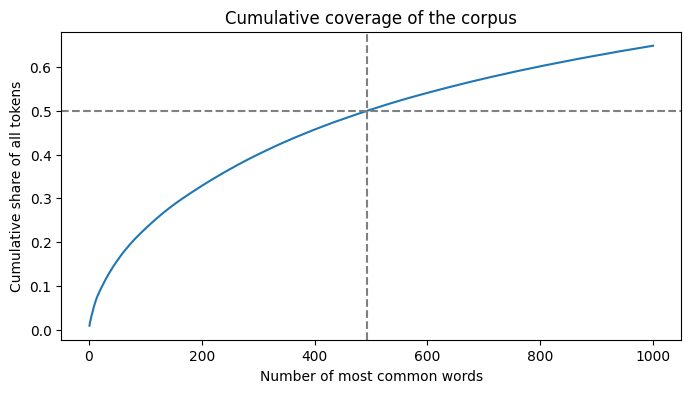

In [18]:
# freq = pd.DataFrame(counts.most_common(), columns=["word", "count"])
freq = pd.DataFrame(filtered_counts.most_common(), columns=["word", "count"])
freq["rank"] = np.arange(1, len(freq) + 1)
freq["rel_freq"] = freq["count"] / total_tokens
freq["cum_share"] = freq["rel_freq"].cumsum()

n_half = int((freq["cum_share"] < 0.5).sum() + 1)
print(f"{n_half} unique words account for 50% of all {total_tokens:,} tokens "
      f"({n_half/unique_words:.2%} of the vocabulary).")

plt.figure(figsize=(8, 4))
plt.plot(freq["rank"][:1000], freq["cum_share"][:1000])
plt.axhline(0.5, color="gray", ls="--")
plt.axvline(n_half, color="gray", ls="--")
plt.xlabel("Number of most common words")
plt.ylabel("Cumulative share of all tokens")
plt.title("Cumulative coverage of the corpus")
plt.show()

#### 493 words account for 50% of the 54,597 content tokens. That is about 5.6% of the filtered vocabulary. The notebook prints 5.39%, but that divides by the pre-filter count of 9,155. The correct figure is 493 / 8,815. The cumulative curve rises steeply

## 4. The 200 highest-frequency words

In [22]:
top200 = freq.head(200).copy()
top200[["rank", "word", "count", "rel_freq"]]

,rank,word,count,rel_freq
0,1,year,472,0.008645
1,2,game,420,0.007693
2,3,think,322,0.005898
3,4,team,305,0.005586
4,5,good,293,0.005367
5,6,games,281,0.005147
6,7,time,264,0.004835
7,8,like,262,0.004799
8,9,baseball,262,0.004799
9,10,hit,246,0.004506


#### The top words are what you would expect from baseball talk: year, game, team, games, baseball, hit, players, runs, league, season, pitching, braves, cubs. The top word, “year”, is only 0.86% of tokens, and relative frequency falls quickly. Rank 1 is about 4.7 times as frequent as rank 60 (0.0018). Some entries are noise, not real vocabulary: b, th, edu, that’s. These are leftover header or signature fragments and contractions that the stopword list missed.

## 5. Relative frequency of the top 200 words

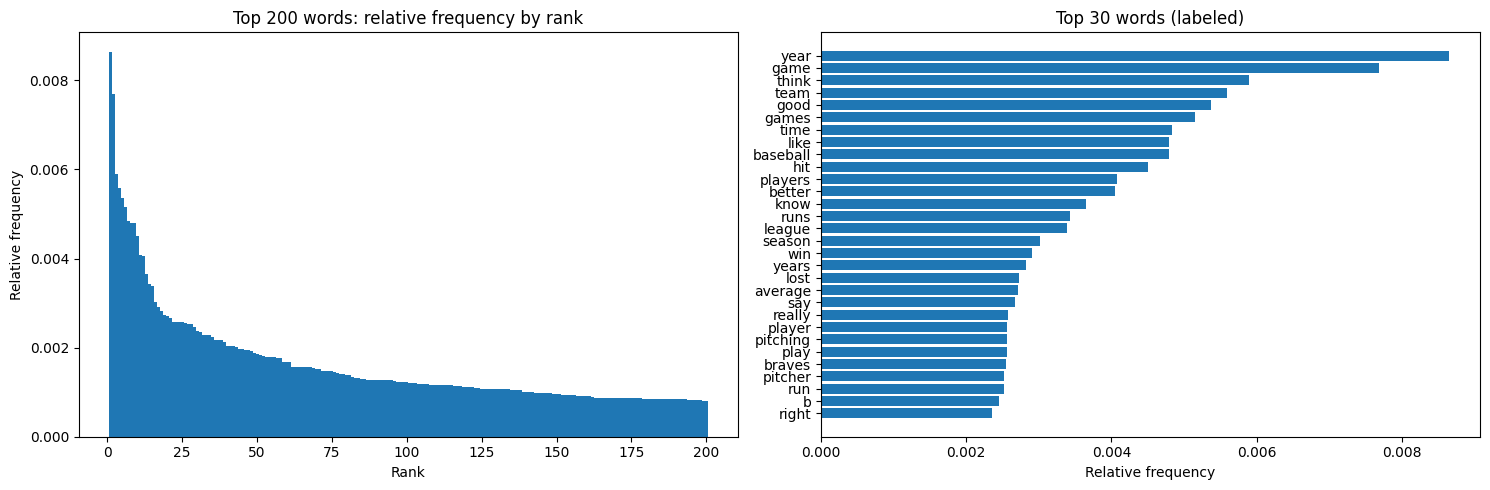

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: all 200 words by rank
axes[0].bar(top200["rank"], top200["rel_freq"], width=1.0)
axes[0].set_xlabel("Rank")
axes[0].set_ylabel("Relative frequency")
axes[0].set_title("Top 200 words: relative frequency by rank")

# Right: top 30 with labels
top30 = top200.head(30).iloc[::-1]
axes[1].barh(top30["word"], top30["rel_freq"])
axes[1].set_xlabel("Relative frequency")
axes[1].set_title("Top 30 words (labeled)")

plt.tight_layout()
plt.show()

#### Relative frequency by rank - The chart is a steeply falling curve that quickly flattens into a long tail.
##### - A sharp drop at the top. Rank 1 (“year”) is about 0.0086 of all tokens. By rank 3 the value is about 0.006, and by rank 15-20 it is about 0.003. Roughly the first 15 words account for most of the vertical drop.
##### - A gradual decline after that. From about rank 25 onward the curve slopes down slowly, reaching about 0.0008 at rank 200.
##### - A staircase shape. The bars step down in small plateaus because many words share the same raw count. For example, ranks 22-28 all have counts of 138-141.
##### - Overall shape. The pattern is heavy-tailed and Zipf-like, which is typical of word frequencies. But the decline is gentler than a true 1/r curve. Frequency falls only about 10x between rank 1 and rank 200, where an ideal Zipf curve would fall about 200x. This is the same flat head that gave the shallow slopes (-0.48 to -0.68) and removing stopwords contributes to it.
#### Top 30 labeled words
##### The top words fall into three groups:
##### - Baseball vocabulary: game, team, games, baseball, hit, players, runs, league, season, win, pitching, player, pitcher, braves. These confirm the topic of the corpus.
##### - General conversational words: year, think, good, time, like, better, know, say, really, right. Newsgroup posts are opinion-heavy (“I think...”, “he’s better...”), so informal discussion words rank alongside baseball terms. “Year” being #1 reflects constant talk of seasons, stats, and years of experience.
##### - Noise: b (rank 29) is a leftover fragment, probably from stats lines like “1b”, “2b” or from signatures. It is not a real word and should be filtered.

## 6. Does it follow Zipf's law?
#### Zipf's law says frequency is roughly inversely proportional to rank: `f(r) ≈ C / r^s` with `s ≈ 1`. On a log-log plot that is a straight line with slope about -1. I fit a line to the log-log data and compare it with the ideal `1/r` curve anchored at the most common word.

Fitted slope, ranks 1-100: -0.481
Fitted slope, ranks 1-1000: -0.676
Fitted slope, ranks 1-8815: -1.090


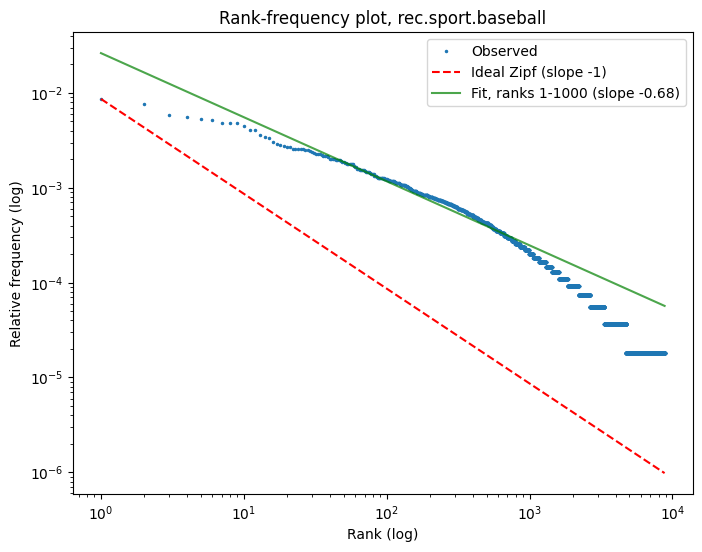

In [24]:
log_r = np.log10(freq["rank"])
log_f = np.log10(freq["rel_freq"])

def fit(lo, hi):
    mask = (freq["rank"] >= lo) & (freq["rank"] <= hi)
    slope, intercept = np.polyfit(log_r[mask], log_f[mask], 1)
    return slope, intercept

for lo, hi in [(1, 100), (1, 1000), (1, len(freq))]:
    s, _ = fit(lo, hi)
    print(f"Fitted slope, ranks {lo}-{hi}: {s:.3f}")

slope, intercept = fit(1, 1000)
ideal = freq["rel_freq"].iloc[0] / freq["rank"]   # perfect Zipf, s = 1

plt.figure(figsize=(8, 6))
plt.loglog(freq["rank"], freq["rel_freq"], ".", ms=3, label="Observed")
plt.loglog(freq["rank"], ideal, "r--", label="Ideal Zipf (slope -1)")
plt.loglog(freq["rank"], 10**(intercept + slope*log_r), "g-", alpha=0.7,
           label=f"Fit, ranks 1-1000 (slope {slope:.2f})")
plt.xlabel("Rank (log)")
plt.ylabel("Relative frequency (log)")
plt.title("Rank-frequency plot, rec.sport.baseball")
plt.legend()
plt.show()

#### The corpus follows Zipf’s law only loosely. It has the heavy-tailed shape Zipf describes, where a few words are very frequent and most words are rare, but the slope does not match the predicted value of about -1 over the part of the ranking where the data is reliable.
#### The data is consistent with a Zipf-like (heavy-tailed) distribution but does not fit the ideal s ≈ 1 law. The log-log plot is curved, not a straight line with slope -1. The observed frequencies sit above the ideal 1/r line in the middle ranks and fall below it in the tail. Zipf’s law is best treated here as a rough approximation of the overall shape.

## 7. How does this differ from "all words in all corpora"?
#### As a stand-in for general English, I compare against the Brown Corpus (1M words, balanced across genres). For each word I compute occurrences per million words in both corpora, then look at the words most over-represented in baseball talk.

In [25]:
import nltk
nltk.download("brown", quiet=True)
from nltk.corpus import brown

brown_counts = Counter(w.lower() for w in brown.words() if w.isalpha())
brown_total = sum(brown_counts.values())

cmp = freq[freq["count"] >= 30][["word", "count"]].copy()
cmp["baseball_per_million"] = cmp["count"] / total_tokens * 1e6
# +1 smoothing so words missing from Brown don't divide by zero
cmp["brown_per_million"] = cmp["word"].map(lambda w: (brown_counts.get(w, 0) + 1) / brown_total * 1e6)
cmp["ratio"] = cmp["baseball_per_million"] / cmp["brown_per_million"]

print("Most over-represented in baseball talk:")
display(cmp.sort_values("ratio", ascending=False).head(25))

print("Most under-represented (common in Brown, rare in baseball talk):")
display(cmp.sort_values("ratio").head(15))

Most over-represented in baseball talk:


,word,count,baseball_per_million,brown_per_million,ratio
46,th,106,1941.498617,1.018625,1906.000256
45,that's,106,1941.498617,1.018625,1906.000256
55,stats,98,1794.970420,1.018625,1762.151180
56,edu,97,1776.654395,1.018625,1744.170046
65,can't,85,1556.862099,1.018625,1528.396432
77,jays,77,1410.333901,1.018625,1384.547356
81,gant,73,1337.069802,1.018625,1312.622818
92,st,69,1263.805704,1.018625,1240.698280
124,nl,59,1080.645457,1.018625,1060.886935
132,alomar,58,1062.329432,1.018625,1042.905801


Most under-represented (common in Brown, rare in baseball talk):


,word,count,baseball_per_million,brown_per_million,ratio
222,man,42,769.273037,1230.498433,0.625172
67,said,85,1556.862099,1998.541330,0.778999
153,world,51,934.117259,802.676130,1.163754
215,old,43,787.589062,674.329439,1.167959
219,american,42,769.273037,580.615983,1.324926
203,use,44,805.905086,603.025722,1.336436
31,new,125,2289.503086,1666.469733,1.373864
258,went,39,714.324963,517.461262,1.380441
190,place,46,842.537136,581.634607,1.448568
114,work,63,1153.909555,777.210517,1.484681


#### After stopword removal reassigned total_tokens to 54,597, so baseball per-million counts use a filtered denominator. Brown’s denominator still includes all its stopwords. This inflates every baseball rate by roughly 2.1x (115,436 / 54,597). That is why the “most under-represented” table is mostly words with ratios above 1 (new, little, work). Only man and said fall below 1, and they would be lower with a fair comparison. I can either filter Brown with the same stopword set or compare against unfiltered baseball counts.

### Conclusion
#### Word frequencies in the baseball newsgroup follow a heavy-tailed, Zipf-like pattern: a few hundred words carry half the text, and nearly half the vocabulary appears only once. However, it does not follow Zipf’s law cleanly. The slope is -0.48 to -0.68 over the dense part of the ranking and reaches -1.09 only when the sparse tail is included. Part of the shallow head is due to removing stopwords, which strips out the most frequent words that normally anchor the Zipf line.
#### Compared with general English (Brown), the corpus is distinguished by team names, player names, and statistics terms (rbi, obp, bullpen, hitter). The most extreme ratios, though, mostly reflect tokenization and corpus differences, so only the domain-specific words should be interpreted as real topical signal.